In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("dianatofficial/football-match-analytics-benchmark-2026")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\siriu\.cache\kagglehub\datasets\dianatofficial\football-match-analytics-benchmark-2026\versions\2


In [2]:
import os
import pandas as pd

# 1. Definisci i percorsi corretti unendo la cartella base alla sottocartella 'data'
matches_path = os.path.join(path, "data", "matches.csv")
leagues_path = os.path.join(path, "data", "leagues.csv")
clubs_path = os.path.join(path, "data", "clubs.csv")
analytics_path = os.path.join(path, "data", "analytics_methods.csv")

# 2. Carica i singoli file in quattro DataFrame distinti
df_matches = pd.read_csv(matches_path)
df_leagues = pd.read_csv(leagues_path)
df_clubs = pd.read_csv(clubs_path)
df_analytics = pd.read_csv(analytics_path)

# 3. Verifica rapida del caricamento di una delle tabelle
print("Tabelle caricate con successo!")
df_leagues.head()

Tabelle caricate con successo!


,league,country,clubs,avg_goals_per_match
0,EuroSim Premier,England,20,5.0
1,EuroSim Liga,Spain,20,4.6
2,EuroSim Serie,Italy,20,4.2
3,EuroSim Bundesliga,Germany,18,4.4
4,EuroSim Ligue,France,18,3.8


In [3]:

df_matches.head()




,match_id,season,league,match_date,home_club,away_club,goals_home,goals_away,result,xg_home,xg_away,shots_home,shots_away,possession_home_pct,yellow_cards_home,yellow_cards_away,btts,over_2_5,attendance,total_goals
0,1,2025,EuroSim Liga,2025-10-07,Torrealta FC,Cuencа FC,1,0,home win,1.78,0.93,11,3,33.0,1,1,False,False,24559,1
1,2,2023,EuroSim Primeira,2024-04-15,CD Serraclaro,AC Duoro Nova,1,0,home win,1.16,0.98,10,3,63.0,2,1,False,False,12611,1
2,3,2026,EuroSim Primeira,2026-10-15,SC Covões,FC Corvina,0,0,draw,1.24,0.49,3,3,33.0,1,1,False,False,25950,0
3,4,2025,EuroSim Primeira,2025-09-09,FC Sapoal,SC Ribeirinha,0,0,draw,0.64,0.97,3,3,40.0,1,0,False,False,22382,0
4,5,2023,EuroSim Premier,2024-03-11,Ockley Town,Wexford Town,0,1,away win,2.02,0.40,3,11,52.0,1,4,False,False,51981,1


In [4]:
df_matches.columns

Index(['match_id', 'season', 'league', 'match_date', 'home_club', 'away_club',
       'goals_home', 'goals_away', 'result', 'xg_home', 'xg_away',
       'shots_home', 'shots_away', 'possession_home_pct', 'yellow_cards_home',
       'yellow_cards_away', 'btts', 'over_2_5', 'attendance', 'total_goals'],
      dtype='str')

In [5]:

df_analytics.columns

Index(['method', 'description'], dtype='str')

In [6]:
df_leagues.columns

df_leagues.head()




,league,country,clubs,avg_goals_per_match
0,EuroSim Premier,England,20,5.0
1,EuroSim Liga,Spain,20,4.6
2,EuroSim Serie,Italy,20,4.2
3,EuroSim Bundesliga,Germany,18,4.4
4,EuroSim Ligue,France,18,3.8


In [7]:
df_clubs.columns

df_clubs.head()


,league,club,country,league_clubs
0,EuroSim Premier,Thames FC,England,20
1,EuroSim Premier,Kingsley United,England,20
2,EuroSim Premier,Northgate City,England,20
3,EuroSim Premier,Redcliffe Rovers,England,20
4,EuroSim Premier,Ashford Athletic,England,20


In [8]:
df_matches.shape



(100000, 20)

In [9]:
df_matches.shape


(100000, 20)

In [10]:
df_clubs.shape

(164, 4)

In [11]:
df_leagues.shape

(8, 4)

In [12]:
df_total =pd.merge(df_matches, df_clubs, left_on="home_club",right_on="club",how="left")


df_total.head()


,match_id,season,league_x,match_date,home_club,away_club,goals_home,goals_away,result,xg_home,...,yellow_cards_home,yellow_cards_away,btts,over_2_5,attendance,total_goals,league_y,club,country,league_clubs
0,1,2025,EuroSim Liga,2025-10-07,Torrealta FC,Cuencа FC,1,0,home win,1.78,...,1,1,False,False,24559,1,EuroSim Liga,Torrealta FC,Spain,20
1,2,2023,EuroSim Primeira,2024-04-15,CD Serraclaro,AC Duoro Nova,1,0,home win,1.16,...,2,1,False,False,12611,1,EuroSim Primeira,CD Serraclaro,Portugal,18
2,3,2026,EuroSim Primeira,2026-10-15,SC Covões,FC Corvina,0,0,draw,1.24,...,1,1,False,False,25950,0,EuroSim Primeira,SC Covões,Portugal,18
3,4,2025,EuroSim Primeira,2025-09-09,FC Sapoal,SC Ribeirinha,0,0,draw,0.64,...,1,0,False,False,22382,0,EuroSim Primeira,FC Sapoal,Portugal,18
4,5,2023,EuroSim Premier,2024-03-11,Ockley Town,Wexford Town,0,1,away win,2.02,...,1,4,False,False,51981,1,EuroSim Premier,Ockley Town,England,20


In [13]:
df_total.shape

(100000, 24)

In [14]:
df_total.shape

(100000, 24)

In [15]:
df_total=pd.merge(df_total, df_leagues, left_on="league_x" , right_on= "league", how="left")



In [16]:
df_total.head()

,match_id,season,league_x,match_date,home_club,away_club,goals_home,goals_away,result,xg_home,...,attendance,total_goals,league_y,club,country_x,league_clubs,league,country_y,clubs,avg_goals_per_match
0,1,2025,EuroSim Liga,2025-10-07,Torrealta FC,Cuencа FC,1,0,home win,1.78,...,24559,1,EuroSim Liga,Torrealta FC,Spain,20,EuroSim Liga,Spain,20,4.6
1,2,2023,EuroSim Primeira,2024-04-15,CD Serraclaro,AC Duoro Nova,1,0,home win,1.16,...,12611,1,EuroSim Primeira,CD Serraclaro,Portugal,18,EuroSim Primeira,Portugal,18,2.5
2,3,2026,EuroSim Primeira,2026-10-15,SC Covões,FC Corvina,0,0,draw,1.24,...,25950,0,EuroSim Primeira,SC Covões,Portugal,18,EuroSim Primeira,Portugal,18,2.5
3,4,2025,EuroSim Primeira,2025-09-09,FC Sapoal,SC Ribeirinha,0,0,draw,0.64,...,22382,0,EuroSim Primeira,FC Sapoal,Portugal,18,EuroSim Primeira,Portugal,18,2.5
4,5,2023,EuroSim Premier,2024-03-11,Ockley Town,Wexford Town,0,1,away win,2.02,...,51981,1,EuroSim Premier,Ockley Town,England,20,EuroSim Premier,England,20,5.0


In [17]:
print(df_total.isnull().sum())
#Conteggio esatto dei valori Nulli/NaN per ogni singola colonna

match_id               0
season                 0
league_x               0
match_date             0
home_club              0
away_club              0
goals_home             0
goals_away             0
result                 0
xg_home                0
xg_away                0
shots_home             0
shots_away             0
possession_home_pct    0
yellow_cards_home      0
yellow_cards_away      0
btts                   0
over_2_5               0
attendance             0
total_goals            0
league_y               0
club                   0
country_x              0
league_clubs           0
league                 0
country_y              0
clubs                  0
avg_goals_per_match    0
dtype: int64


In [18]:
#Statistiche di TUTTE le colonne (incluse quelle testuali/oggetti con include='all')
print(df_total.describe(include="all"))

             match_id         season         league_x  match_date  \
count   100000.000000  100000.000000           100000      100000   
unique            NaN            NaN                8        2320   
top               NaN            NaN  EuroSim Premier  2026-03-12   
freq              NaN            NaN            16429          73   
mean     50000.500000    2022.915880              NaN         NaN   
std      28867.657797       2.250856              NaN         NaN   
min          1.000000    2019.000000              NaN         NaN   
25%      25000.750000    2021.000000              NaN         NaN   
50%      50000.500000    2023.000000              NaN         NaN   
75%      75000.250000    2025.000000              NaN         NaN   
max     100000.000000    2026.000000              NaN         NaN   

           home_club     away_club     goals_home     goals_away    result  \
count         100000        100000  100000.000000  100000.000000    100000   
unique         

In [19]:
df_total.columns

Index(['match_id', 'season', 'league_x', 'match_date', 'home_club',
       'away_club', 'goals_home', 'goals_away', 'result', 'xg_home', 'xg_away',
       'shots_home', 'shots_away', 'possession_home_pct', 'yellow_cards_home',
       'yellow_cards_away', 'btts', 'over_2_5', 'attendance', 'total_goals',
       'league_y', 'club', 'country_x', 'league_clubs', 'league', 'country_y',
       'clubs', 'avg_goals_per_match'],
      dtype='str')

In [20]:
df_total=df_total.drop(columns=["league_y", "club", "league_clubs", "league", "country_y"], errors="ignore")

In [21]:
df_total.columns


Index(['match_id', 'season', 'league_x', 'match_date', 'home_club',
       'away_club', 'goals_home', 'goals_away', 'result', 'xg_home', 'xg_away',
       'shots_home', 'shots_away', 'possession_home_pct', 'yellow_cards_home',
       'yellow_cards_away', 'btts', 'over_2_5', 'attendance', 'total_goals',
       'country_x', 'clubs', 'avg_goals_per_match'],
      dtype='str')

In [22]:
df_total.rename(columns={"league_x":"league"}, inplace=True)

In [23]:
df_total.columns

Index(['match_id', 'season', 'league', 'match_date', 'home_club', 'away_club',
       'goals_home', 'goals_away', 'result', 'xg_home', 'xg_away',
       'shots_home', 'shots_away', 'possession_home_pct', 'yellow_cards_home',
       'yellow_cards_away', 'btts', 'over_2_5', 'attendance', 'total_goals',
       'country_x', 'clubs', 'avg_goals_per_match'],
      dtype='str')

In [24]:
df_total.shape

(100000, 23)

In [25]:
df_media_goal= df_total["total_goals"].mean()
print(df_media_goal)

2.72427


In [26]:
df_total.head()

,match_id,season,league,match_date,home_club,away_club,goals_home,goals_away,result,xg_home,...,possession_home_pct,yellow_cards_home,yellow_cards_away,btts,over_2_5,attendance,total_goals,country_x,clubs,avg_goals_per_match
0,1,2025,EuroSim Liga,2025-10-07,Torrealta FC,Cuencа FC,1,0,home win,1.78,...,33.0,1,1,False,False,24559,1,Spain,20,4.6
1,2,2023,EuroSim Primeira,2024-04-15,CD Serraclaro,AC Duoro Nova,1,0,home win,1.16,...,63.0,2,1,False,False,12611,1,Portugal,18,2.5
2,3,2026,EuroSim Primeira,2026-10-15,SC Covões,FC Corvina,0,0,draw,1.24,...,33.0,1,1,False,False,25950,0,Portugal,18,2.5
3,4,2025,EuroSim Primeira,2025-09-09,FC Sapoal,SC Ribeirinha,0,0,draw,0.64,...,40.0,1,0,False,False,22382,0,Portugal,18,2.5
4,5,2023,EuroSim Premier,2024-03-11,Ockley Town,Wexford Town,0,1,away win,2.02,...,52.0,1,4,False,False,51981,1,England,20,5.0


In [27]:
goleada = df_total[ df_total["total_goals"]>5]

print("Quante:", goleada.shape[0])

goleada.head()

Quante: 7003


,match_id,season,league,match_date,home_club,away_club,goals_home,goals_away,result,xg_home,...,possession_home_pct,yellow_cards_home,yellow_cards_away,btts,over_2_5,attendance,total_goals,country_x,clubs,avg_goals_per_match
12,13,2026,EuroSim Bundesliga,2027-04-28,TSV Grünwald,Borussia Lindenthal,3,3,draw,1.77,...,58.0,3,4,True,True,36666,6,Germany,18,4.4
20,21,2024,EuroSim Premier,2025-05-03,Wexford Town,Harrow FC,3,3,draw,2.75,...,60.0,1,1,True,True,33346,6,England,20,5.0
22,23,2026,EuroSim Serie,2027-01-10,Interduno,US Ravenna,4,3,home win,1.31,...,76.0,1,2,True,True,33006,7,Italy,20,4.2
24,25,2022,EuroSim Premier,2022-08-31,Marlow City,Bramley FC,5,1,home win,2.03,...,31.0,0,0,True,True,40105,6,England,20,5.0
25,26,2025,EuroSim Premier,2026-01-07,Marlow City,Silverton FC,5,2,home win,1.65,...,65.0,0,1,True,True,30288,7,England,20,5.0


In [28]:
df_total["scarto"]=abs(df_total["goals_home"]- df_total["goals_away"])

In [29]:
df_total["scarto"]

0        1
1        1
2        0
3        0
4        1
        ..
99995    0
99996    1
99997    0
99998    1
99999    0
Name: scarto, Length: 100000, dtype: int64

In [30]:
con_vincitore = df_total[df_total["result"]!= "draw"]


In [31]:

con_vincitore["scarto"].mean()

np.float64(1.7606710781364883)

In [32]:
trasferta=df_total.groupby("away_club")["goals_away"].sum()

In [33]:
casa = df_total.groupby("home_club")["goals_home"].sum()


In [34]:
totale=casa+trasferta

print(totale)

home_club
 Sporting Ardennes    1621
AC Duoro Nova          719
AC Ligure             1826
AD Figueira            730
AS Clairval           1592
                      ... 
Wexley FC              667
Whitmore Athletic     2837
Yarborough City        649
Zafra CF              2453
Étoile Noire FC       1663
Length: 164, dtype: int64


In [35]:
classifica= totale.sort_values(ascending=False).head(10)
print(classifica)


home_club
Granton Rovers       2990
Thames FC            2941
Bramley FC           2907
Wexford Town         2883
Ashford Athletic     2867
Eastport United      2863
Stonebridge FC       2861
Silverton FC         2855
Harrow FC            2852
Whitmore Athletic    2837
dtype: int64


In [36]:
drill= pd.DataFrame({"casa":casa, "trasferta":trasferta,"totale":totale})

drill.sort_values("totale", ascending=False).head(10)

,casa,trasferta,totale
Granton Rovers,1730,1260,2990
Thames FC,1714,1227,2941
Bramley FC,1669,1238,2907
Wexford Town,1619,1264,2883
Ashford Athletic,1660,1207,2867
Eastport United,1678,1185,2863
Stonebridge FC,1619,1242,2861
Silverton FC,1732,1123,2855
Harrow FC,1694,1158,2852
Whitmore Athletic,1615,1222,2837


<Axes: title={'center': 'Top 10 Club 2019-2026'}, ylabel='home_club'>

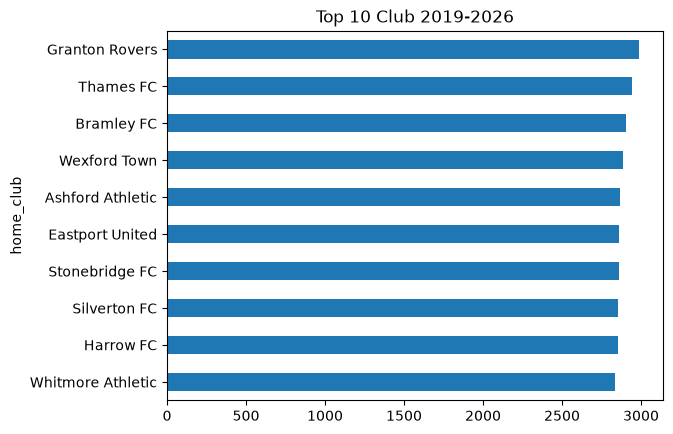

In [37]:
classifica.sort_values().plot(kind="barh", title="Top 10 Club 2019-2026")



In [38]:
stats_casa=df_total.groupby(["season","home_club" ]).agg(
    giocate_casa=("match_id", "count"), 
    fatti_casa=("goals_home","sum"), 
    subiti_casa=("goals_away","sum"),).reset_index()

In [39]:
stats_casa.head()

,season,home_club,giocate_casa,fatti_casa,subiti_casa
0,2019,Sporting Ardennes,52,98,53
1,2019,AC Duoro Nova,38,40,24
2,2019,AC Ligure,62,102,91
3,2019,AD Figueira,38,42,31
4,2019,AS Clairval,71,105,85


In [40]:
stats_casa.shape

(1312, 5)

In [41]:
stats_trasferta = df_total.groupby(["season","away_club"]).agg(
    giocate_trasferta=("match_id", "count"),
    fatti_trasferta =("goals_away","sum"),
    subiti_trasferta=("goals_home", "sum")
    ).reset_index()

In [42]:
stats_trasferta.shape

(1312, 5)

In [43]:
stats_trasferta.head()


,season,away_club,giocate_trasferta,fatti_trasferta,subiti_trasferta
0,2019,Sporting Ardennes,56,81,84
1,2019,AC Duoro Nova,32,22,24
2,2019,AC Ligure,59,71,120
3,2019,AD Figueira,36,30,34
4,2019,AS Clairval,56,56,97


In [44]:
stats_club=pd.merge(stats_casa, stats_trasferta, left_on=["season","home_club"], right_on=["season","away_club"],
how="left")
# pulizia subito dopo il merge: away_club duplica home_club, poi rinomina in club
stats_club = stats_club.drop(columns=["away_club"]).rename(columns={"home_club": "club"})
stats_club.shape  # atteso (1312, 8): chiave doppia unica, niente duplicazioni

(1312, 8)

In [45]:
# (cella svuotata: diff_reti viene calcolata nella cella delle metriche derivate, piu' avanti)

In [46]:
stats_club.shape

stats_club.rename(columns={"home_club":"club"}, inplace=True)

stats_club.head()

,season,club,giocate_casa,fatti_casa,subiti_casa,giocate_trasferta,fatti_trasferta,subiti_trasferta
0,2019,Sporting Ardennes,52,98,53,56,81,84
1,2019,AC Duoro Nova,38,40,24,32,22,24
2,2019,AC Ligure,62,102,91,59,71,120
3,2019,AD Figueira,38,42,31,36,30,34
4,2019,AS Clairval,71,105,85,56,56,97


In [47]:
stats_club=stats_club.sort_values(["club","season"])

In [48]:

feature_cols=["gol_fatti_media","gol_subiti_media","diff_reti","partite"]

stats_shift=stats_club.copy()


In [49]:
print(stats_club.columns.tolist())

['season', 'club', 'giocate_casa', 'fatti_casa', 'subiti_casa', 'giocate_trasferta', 'fatti_trasferta', 'subiti_trasferta']


In [50]:
stats_club["gol_fatti"]=stats_club["fatti_casa"] + stats_club["fatti_trasferta"]
stats_club["gol_subiti"]=stats_club["subiti_casa"]+stats_club["subiti_trasferta"]
stats_club["partite"]=stats_club["giocate_casa"]+stats_club["giocate_trasferta"]
stats_club["gol_fatti_media"]=stats_club["gol_fatti"]/stats_club["partite"]
stats_club["gol_subiti_media"]=stats_club["gol_subiti"]/stats_club ["partite"]
stats_club["diff_reti"]=stats_club["gol_fatti"]-stats_club["gol_subiti"]

In [51]:
stats_shift[feature_cols]=stats_club.groupby("club")[feature_cols].shift(1)

In [52]:
stats_shift.head(10)

,season,club,giocate_casa,fatti_casa,subiti_casa,giocate_trasferta,fatti_trasferta,subiti_trasferta,gol_fatti_media,gol_subiti_media,diff_reti,partite
0,2019,Sporting Ardennes,52,98,53,56,81,84,NaN,NaN,NaN,NaN
164,2020,Sporting Ardennes,42,59,39,68,77,114,1.657407,1.268519,42.0,108.0
328,2021,Sporting Ardennes,68,96,71,68,80,88,1.236364,1.390909,-17.0,110.0
492,2022,Sporting Ardennes,60,87,77,81,96,124,1.294118,1.169118,17.0,136.0
656,2023,Sporting Ardennes,82,102,86,66,78,98,1.297872,1.425532,-18.0,141.0
820,2024,Sporting Ardennes,98,127,91,100,106,138,1.216216,1.243243,-4.0,148.0
984,2025,Sporting Ardennes,103,168,96,104,106,133,1.176768,1.156566,4.0,198.0
1148,2026,Sporting Ardennes,110,158,118,99,102,139,1.323671,1.106280,45.0,207.0
1,2019,AC Duoro Nova,38,40,24,32,22,24,NaN,NaN,NaN,NaN
165,2020,AC Duoro Nova,40,39,26,50,32,49,0.885714,0.685714,14.0,70.0


In [53]:
stats_shift.shape

(1312, 12)

In [54]:
stats_shift=stats_shift.dropna(subset=feature_cols)

In [55]:
stats_shift.shape

(1148, 12)

In [56]:
ml= df_total[["season","league", "home_club", "away_club", "result"]].copy()

ml=pd.merge(ml,stats_shift[["season","club"]+feature_cols],left_on=["season","home_club"], right_on=["season","club"], how="inner")

In [57]:
ml=pd.merge(ml, stats_shift[["season","club"]+feature_cols], left_on=["season","away_club"], right_on=["season","club"], how="inner")

In [58]:
ml=ml.drop(columns=["club"], errors="ignore").rename(columns={c:c+"_away" for c in feature_cols})
ml.columns

Index(['season', 'league', 'home_club', 'away_club', 'result', 'club_x',
       'gol_fatti_media_x', 'gol_subiti_media_x', 'diff_reti_x', 'partite_x',
       'club_y', 'gol_fatti_media_y', 'gol_subiti_media_y', 'diff_reti_y',
       'partite_y'],
      dtype='str')

In [59]:
ml.shape

(90934, 15)

In [60]:
rinomina ={}

for c in feature_cols:
    rinomina[c+"_x"]=c+"_home"
    rinomina[c+"_y"]=c+"_away"

ml=ml.rename(columns=rinomina).drop(columns=["club_x","club_y"])


In [61]:

ml.columns

Index(['season', 'league', 'home_club', 'away_club', 'result',
       'gol_fatti_media_home', 'gol_subiti_media_home', 'diff_reti_home',
       'partite_home', 'gol_fatti_media_away', 'gol_subiti_media_away',
       'diff_reti_away', 'partite_away'],
      dtype='str')

In [62]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,ConfusionMatrixDisplay


In [63]:
feature_ml=[c +"_home" for c in feature_cols]+[c +"_away" for c in feature_cols]

x=ml[feature_ml]
y=ml["result"]

print(y.value_counts())

result
home win    42253
away win    25811
draw        22870
Name: count, dtype: int64


In [64]:
x_train, x_test, y_train, y_test=train_test_split(x,y,test_size=0.2, random_state=42,stratify=y)

rf=RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

Accuracy: 0.38324077637873205
              precision    recall  f1-score   support

    away win       0.28      0.24      0.26      5162
        draw       0.26      0.21      0.23      4574
    home win       0.47      0.57      0.51      8451

    accuracy                           0.38     18187
   macro avg       0.34      0.34      0.34     18187
weighted avg       0.36      0.38      0.37     18187



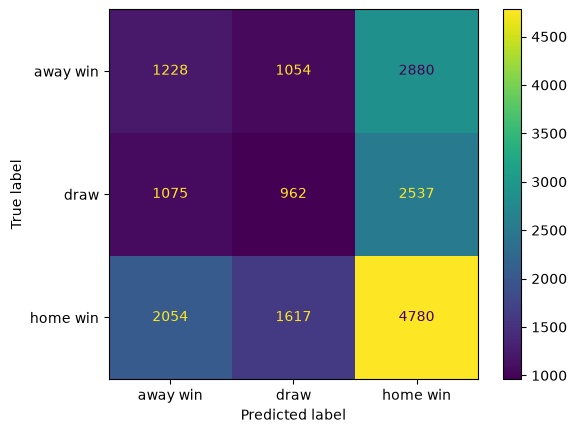

In [65]:
y_pred=rf.predict(x_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=rf.classes_).plot()

<Axes: title={'center': 'Cosa decide una partita?'}>

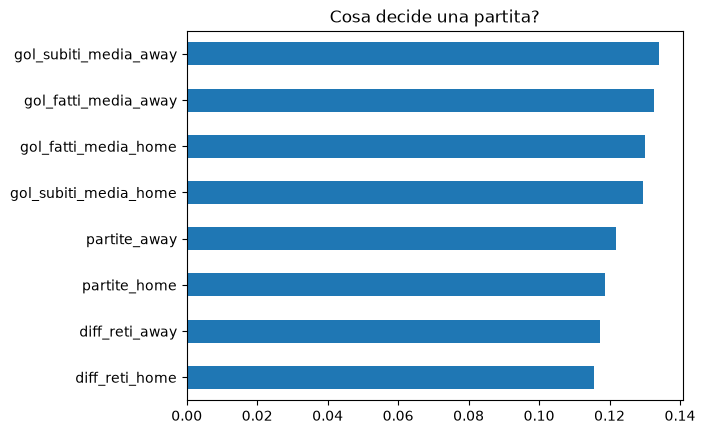

In [66]:
imp= pd.Series(rf.feature_importances_,index=feature_ml).sort_values()
imp.plot(kind="barh", title="Cosa decide una partita?")

In [67]:
# (rimossa: il check di autocorrelazione corretto e' nella cella finale, piu' sotto)

In [68]:
# (rimossa: frammento del check, vedi cella finale)

In [69]:
import matplotlib.pyplot as plt

import seaborn as sns

features_da_controllare = [
    "gol_fatti_media_home", "gol_subiti_media_home", "diff_reti_home", "partite_home",
    "gol_fatti_media_away", "gol_subiti_media_away", "diff_reti_away", "partite_away"
]

# 2. Calcoliamo la matrice di correlazione (Esclude automaticamente i testi come i nomi dei club)
corr_matrix = ml[features_da_controllare].corr()



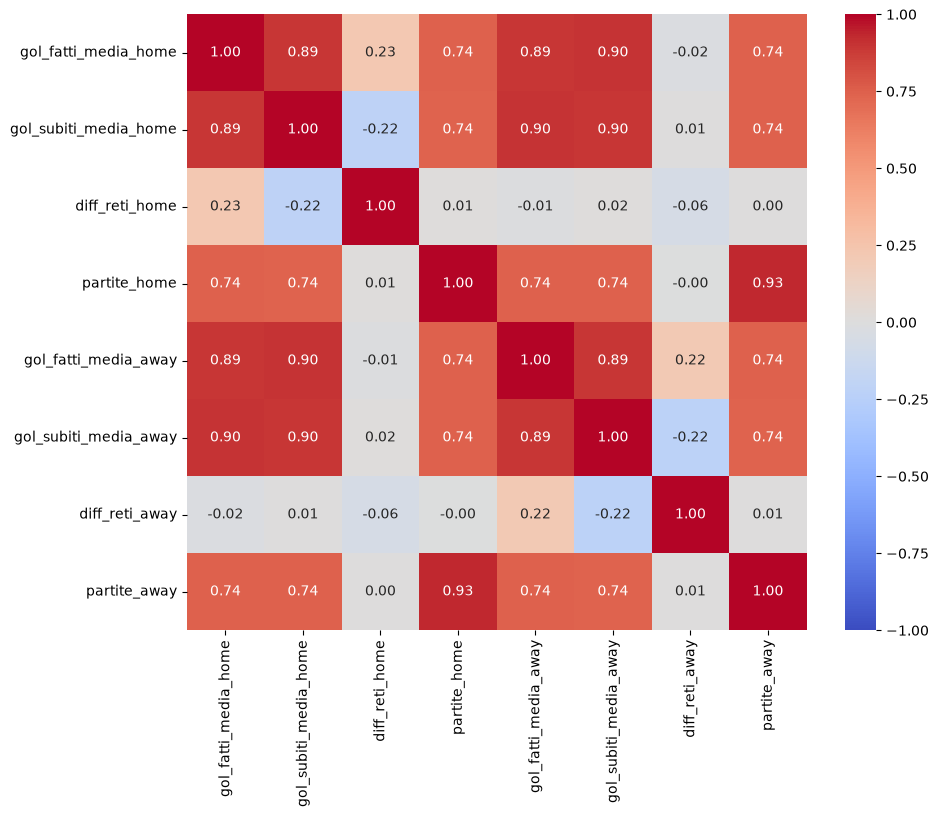

In [70]:
plt.figure(figsize=(10,8))

sns.heatmap(corr_matrix,annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.show()

In [71]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [72]:
rf=RandomForestClassifier(class_weight="balanced",random_state=42)

In [73]:
rf.fit(x_train,y_train)
y_pred=rf.predict(x_test)


In [74]:
print("Nuova Acuuracy:", accuracy_score(y_test,y_pred))
print("\nNuovo Classification Report:")
print(classification_report(y_test,y_pred))

Nuova Acuuracy: 0.3379336888986639

Nuovo Classification Report:
              precision    recall  f1-score   support

    away win       0.28      0.31      0.29      5162
        draw       0.26      0.35      0.30      4574
    home win       0.47      0.35      0.40      8451

    accuracy                           0.34     18187
   macro avg       0.34      0.34      0.33     18187
weighted avg       0.36      0.34      0.34     18187



In [75]:
print(ml["diff_reti_home"].isnull().sum(), ml["diff_reti_away"].isnull().sum())
print(ml["diff_reti_home"].describe())

0 0
count    90934.000000
mean         0.029670
std         22.338008
min        -73.000000
25%        -13.000000
50%         -1.000000
75%         14.000000
max         73.000000
Name: diff_reti_home, dtype: float64


In [76]:
# CHECK FINALE: la forza di un club persiste da un anno all'altro?
s = stats_club.sort_values(["club", "season"])
corr_anno = s.groupby("club")["diff_reti"].apply(lambda x: x.autocorr())
print("Correlazione anno-su-anno media:", corr_anno.dropna().mean())

Correlazione anno-su-anno media: -0.14465768811986982


In [77]:
# (rimossa: il rename home_club -> club ora avviene subito dopo il merge delle statistiche)

In [78]:
print(stats_club.columns.tolist())

['season', 'club', 'giocate_casa', 'fatti_casa', 'subiti_casa', 'giocate_trasferta', 'fatti_trasferta', 'subiti_trasferta', 'gol_fatti', 'gol_subiti', 'partite', 'gol_fatti_media', 'gol_subiti_media', 'diff_reti']
